# PS-12: Fresh vs Rotten Fruit Sorting
**Deep Learning CBL — Image Classification Challenge**

Objective: classify images into six classes: fresh apples, fresh bananas, fresh oranges, rotten apples, rotten bananas, and rotten oranges.

**How to run:** Use Kaggle Notebooks and attach the dataset `Fruits Fresh and Rotten for Classification`, then choose GPU if available. This notebook also supports Google Colab after downloading the dataset and extracting it into `/content/`.

> Dataset source: https://www.kaggle.com/datasets/sriramr/fruits-fresh-and-rotten-for-classification  
> Important PS-12 challenge: inspect errors and discuss whether the model uses spoilage cues or simply fruit-type cues.

## 1. Imports and reproducibility
Run cells from top to bottom. The notebook uses transfer learning (MobileNetV2) to keep training relatively fast.

In [1]:
import os, random, time, pathlib, glob
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay, accuracy_score, f1_score
from sklearn.model_selection import train_test_split

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)
print("TensorFlow:", tf.__version__)
print("GPU devices:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.21.0
GPU devices: []


## 2. Find the dataset folders
Expected classes: `freshapples`, `freshbanana`, `freshoranges`, `rottenapples`, `rottenbanana`, `rottenoranges`. The code searches common Kaggle and Colab locations for a folder containing all six class subfolders.

In [6]:

import os

EXPECTED = {
    "freshapples",
    "freshbanana",
    "freshoranges",
    "rottenapples",
    "rottenbanana",
    "rottenoranges"
}

def find_split_dirs():
    roots = [
        r"C:\Users\Students\Downloads\archive\dataset",
        r"C:\Users\Students\Downloads\archive",
        "/kaggle/input",
        "/content",
        "/content/dataset",
        "/content/data",
        "."
    ]

    candidates = []

    for root in roots:
        if not os.path.exists(root):
            continue

        for current, dirs, files in os.walk(root):
            dirs[:] = [
                d for d in dirs
                if not d.startswith(".")
                and d not in {"node_modules", ".git"}
            ]

            names = {d.lower() for d in dirs}

            if EXPECTED.issubset(names):
                candidates.append(current)

    train_dirs = [
        p for p in candidates
        if os.path.basename(p).lower() in ("train", "training")
    ]

    test_dirs = [
        p for p in candidates
        if os.path.basename(p).lower() in ("test", "testing")
    ]

    if train_dirs and test_dirs:
        train_dir = train_dirs[0]
        test_dir = test_dirs[0]
        print("Train/root folder:", train_dir)
        print("Test folder:", test_dir)
        return train_dir, test_dir

    raise FileNotFoundError(
        "Could not find the train and test folders containing all six classes. "
        "Please check the dataset path."
    )

train_dir, test_dir = find_split_dirs()


Train/root folder: C:\Users\Students\Downloads\archive\dataset\dataset\train
Test folder: C:\Users\Students\Downloads\archive\dataset\dataset\test


## 3. Count images per class and display sample images
These counts and sample images are part of the required exploratory data analysis.

Class names: ['freshapples', 'freshbanana', 'freshoranges', 'rottenapples', 'rottenbanana', 'rottenoranges']
Training/root image counts:
freshapples         : 1693
freshbanana         : 1581
freshoranges        : 1466
rottenapples        : 2342
rottenbanana        : 2224
rottenoranges       : 1595


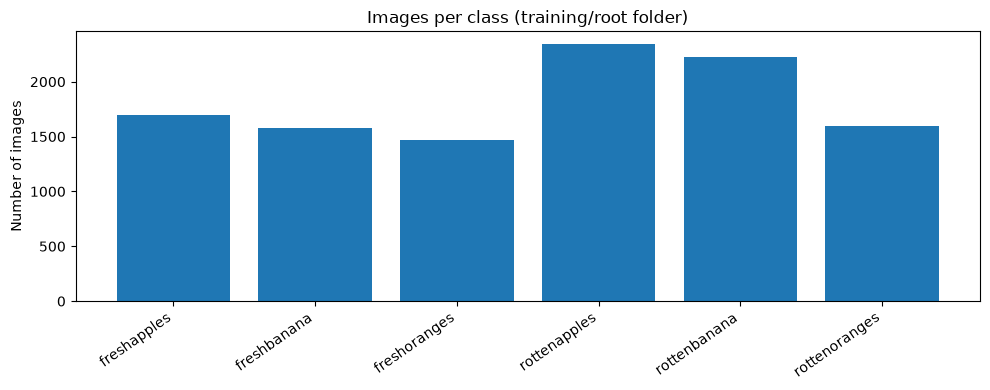

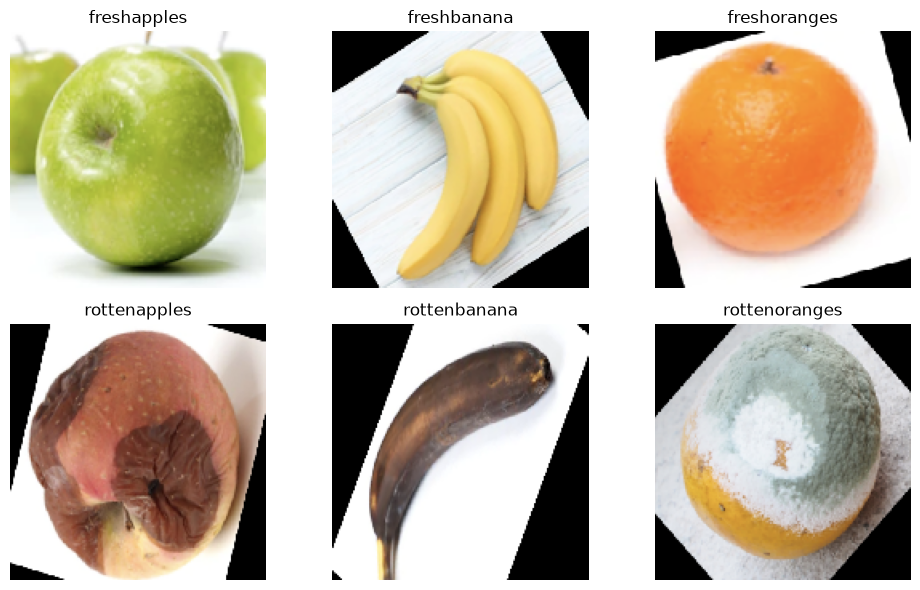

In [4]:
IMG_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
def image_files(folder):
    return [str(p) for p in pathlib.Path(folder).rglob("*") if p.is_file() and p.suffix.lower() in IMG_EXTS]

class_names = sorted([d for d in os.listdir(train_dir) if os.path.isdir(os.path.join(train_dir, d)) and d.lower() in EXPECTED])
if len(class_names) != 6:
    class_names = sorted([d for d in os.listdir(train_dir) if os.path.isdir(os.path.join(train_dir, d))])
print("Class names:", class_names)
counts = {}
for cls in class_names:
    counts[cls] = len(image_files(os.path.join(train_dir, cls)))
print("Training/root image counts:")
for cls, count in counts.items():
    print(f"{cls:20s}: {count}")
plt.figure(figsize=(10, 4))
plt.bar(counts.keys(), counts.values())
plt.xticks(rotation=35, ha="right")
plt.ylabel("Number of images")
plt.title("Images per class (training/root folder)")
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(2, 3, figsize=(10, 6))
for ax, cls in zip(axes.flat, class_names):
    files = image_files(os.path.join(train_dir, cls))
    if files:
        img = keras.utils.load_img(random.choice(files), target_size=(160, 160))
        ax.imshow(img)
        ax.set_title(cls)
    ax.axis("off")
plt.tight_layout()
plt.show()

## 4. Create training, validation and test datasets
If the dataset has predefined `train` and `test` folders, the test folder is held out until final evaluation. Validation is split from training using a fixed seed. If only one class-folder root is available, the notebook makes train/validation/test splits from that root.

In [5]:
IMG_SIZE = (160, 160)
BATCH_SIZE = 32

if test_dir is not None and os.path.abspath(test_dir) != os.path.abspath(train_dir):
    train_ds = keras.utils.image_dataset_from_directory(
        train_dir, validation_split=0.2, subset="training", seed=SEED,
        image_size=IMG_SIZE, batch_size=BATCH_SIZE, label_mode="int"
    )
    val_ds = keras.utils.image_dataset_from_directory(
        train_dir, validation_split=0.2, subset="validation", seed=SEED,
        image_size=IMG_SIZE, batch_size=BATCH_SIZE, label_mode="int"
    )
    test_ds = keras.utils.image_dataset_from_directory(
        test_dir, image_size=IMG_SIZE, batch_size=BATCH_SIZE,
        shuffle=False, label_mode="int"
    )
else:
    # Split paths explicitly to create fixed train/validation/test sets.
    paths, labels = [], []
    for idx, cls in enumerate(class_names):
        files = image_files(os.path.join(train_dir, cls))
        paths.extend(files)
        labels.extend([idx] * len(files))
    train_paths, temp_paths, train_y, temp_y = train_test_split(
        paths, labels, test_size=0.30, random_state=SEED, stratify=labels
    )
    val_paths, test_paths, val_y, test_y = train_test_split(
        temp_paths, temp_y, test_size=0.50, random_state=SEED, stratify=temp_y
    )
    def make_ds(paths, labels, shuffle=False):
        ds = tf.data.Dataset.from_tensor_slices((paths, labels))
        def load(path, label):
            raw = tf.io.read_file(path)
            img = tf.io.decode_image(raw, channels=3, expand_animations=False)
            img.set_shape([None, None, 3])
            img = tf.image.resize(img, IMG_SIZE)
            return img, tf.cast(label, tf.int32)
        ds = ds.map(load, num_parallel_calls=tf.data.AUTOTUNE)
        if shuffle: ds = ds.shuffle(1000, seed=SEED)
        return ds.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)
    train_ds = make_ds(train_paths, train_y, True)
    val_ds = make_ds(val_paths, val_y)
    test_ds = make_ds(test_paths, test_y)

# Keep the class order consistent across all datasets.
class_names = list(train_ds.class_names) if hasattr(train_ds, "class_names") else class_names
print("Classes:", class_names)
print("Training batches:", tf.data.experimental.cardinality(train_ds).numpy())
print("Validation batches:", tf.data.experimental.cardinality(val_ds).numpy())
print("Test batches:", tf.data.experimental.cardinality(test_ds).numpy())

AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.prefetch(AUTOTUNE)
val_ds = val_ds.prefetch(AUTOTUNE)
test_ds = test_ds.prefetch(AUTOTUNE)

Found 10901 files belonging to 6 classes.
Using 8721 files for training.
Found 10901 files belonging to 6 classes.
Using 2180 files for validation.
Found 2698 files belonging to 6 classes.
Classes: ['freshapples', 'freshbanana', 'freshoranges', 'rottenapples', 'rottenbanana', 'rottenoranges']
Training batches: 273
Validation batches: 69
Test batches: 85


## 5. Build a transfer-learning CNN
MobileNetV2 provides pretrained visual features. The classification head is trained for the six fruit-condition classes. Data augmentation is applied only during training.

In [8]:
data_augmentation = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.08),
    layers.RandomZoom(0.10),
], name="training_augmentation")

base_model = keras.applications.MobileNetV2(
    input_shape=IMG_SIZE + (3,), include_top=False, weights="imagenet"
)
base_model.trainable = False

inputs = keras.Input(shape=IMG_SIZE + (3,))
x = data_augmentation(inputs)
x = keras.applications.mobilenet_v2.preprocess_input(x)
x = base_model(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.25)(x)
outputs = layers.Dense(len(class_names), activation="softmax")(x)
model = keras.Model(inputs, outputs)
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)
model.summary()

Model: "functional_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ input_layer_4 (InputLayer)           │ (None, 160, 160, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ training_augmentation (Sequential)   │ (None, 160, 160, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ true_divide_1 (TrueDivide)           │ (None, 160, 160, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ subtract_1 (Subtract)                │ (None, 160, 160, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ mobilenetv2_1.00_160 (Functional)    │ (None, 5, 5, 1280)          │       2,257,984 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_average_pooling2d_1           │ (None, 1280)                │               0 │
│ (GlobalAveragePooling2D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_1 (Dropout)                  │ (None, 1280)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 6)                   │           7,686 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 2,265,670 (8.64 MB)

 Trainable params: 7,686 (30.02 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

## 6. Train the model
The default is five epochs to fit the one-hour deadline. If time is short, reduce `EPOCHS` to 3. Results must be reported from your actual run; do not invent metrics.

In [9]:
EPOCHS = 5
callbacks = [
    keras.callbacks.EarlyStopping(monitor="val_loss", patience=2, restore_best_weights=True),
    keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.3, patience=1, min_lr=1e-6)
]
start_time = time.time()
history = model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS, callbacks=callbacks)
training_seconds = time.time() - start_time
print(f"Training time: {training_seconds/60:.2f} minutes")

Epoch 1/5


C:\Users\Students\PS12_Fruit_Classification\.venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


273/273 ━━━━━━━━━━━━━━━━━━━━ 76s 263ms/step - accuracy: 0.8943 - loss: 0.3124 - val_accuracy: 0.9665 - val_loss: 0.1020 - learning_rate: 0.0010
Epoch 2/5
273/273 ━━━━━━━━━━━━━━━━━━━━ 64s 234ms/step - accuracy: 0.9664 - loss: 0.1040 - val_accuracy: 0.9798 - val_loss: 0.0695 - learning_rate: 0.0010
Epoch 3/5
273/273 ━━━━━━━━━━━━━━━━━━━━ 63s 229ms/step - accuracy: 0.9745 - loss: 0.0764 - val_accuracy: 0.9798 - val_loss: 0.0611 - learning_rate: 0.0010
Epoch 4/5
273/273 ━━━━━━━━━━━━━━━━━━━━ 91s 264ms/step - accuracy: 0.9810 - loss: 0.0614 - val_accuracy: 0.9862 - val_loss: 0.0499 - learning_rate: 0.0010
Epoch 5/5
273/273 ━━━━━━━━━━━━━━━━━━━━ 82s 265ms/step - accuracy: 0.9831 - loss: 0.0525 - val_accuracy: 0.9885 - val_loss: 0.0414 - learning_rate: 0.0010
Training time: 6.43 minutes


## 7. Plot training and validation accuracy/loss

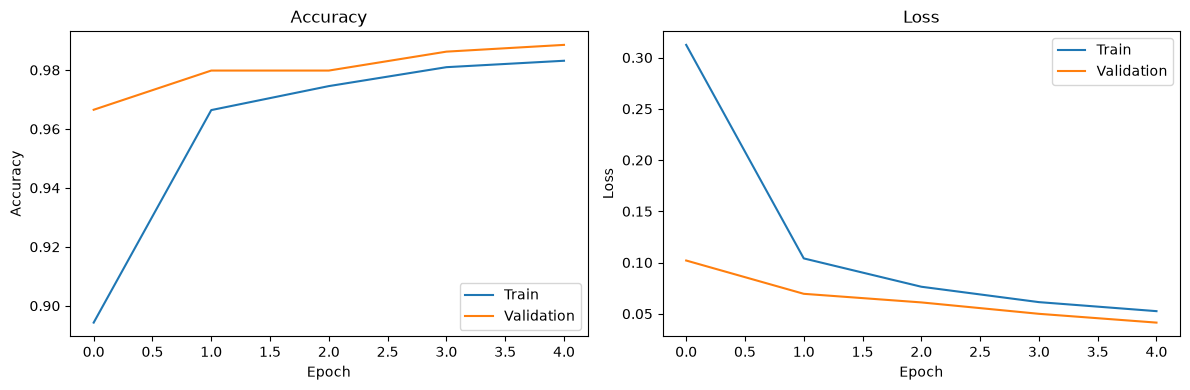

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(history.history["accuracy"], label="Train")
axes[0].plot(history.history["val_accuracy"], label="Validation")
axes[0].set_title("Accuracy")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()
axes[1].plot(history.history["loss"], label="Train")
axes[1].plot(history.history["val_loss"], label="Validation")
axes[1].set_title("Loss")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend()
plt.tight_layout()
plt.show()

## 8. Final evaluation on the held-out test set
This cell calculates test accuracy, per-class precision/recall/F1, macro F1 and a confusion matrix.

85/85 ━━━━━━━━━━━━━━━━━━━━ 16s 181ms/step
TEST accuracy: 0.9848
TEST macro F1: 0.9845

Per-class metrics:
               precision    recall  f1-score   support

  freshapples     0.9656    0.9949    0.9800       395
  freshbanana     1.0000    1.0000    1.0000       381
 freshoranges     0.9947    0.9613    0.9777       388
 rottenapples     0.9800    0.9784    0.9792       601
 rottenbanana     1.0000    1.0000    1.0000       530
rottenoranges     0.9679    0.9727    0.9703       403

     accuracy                         0.9848      2698
    macro avg     0.9847    0.9846    0.9845      2698
 weighted avg     0.9849    0.9848    0.9848      2698



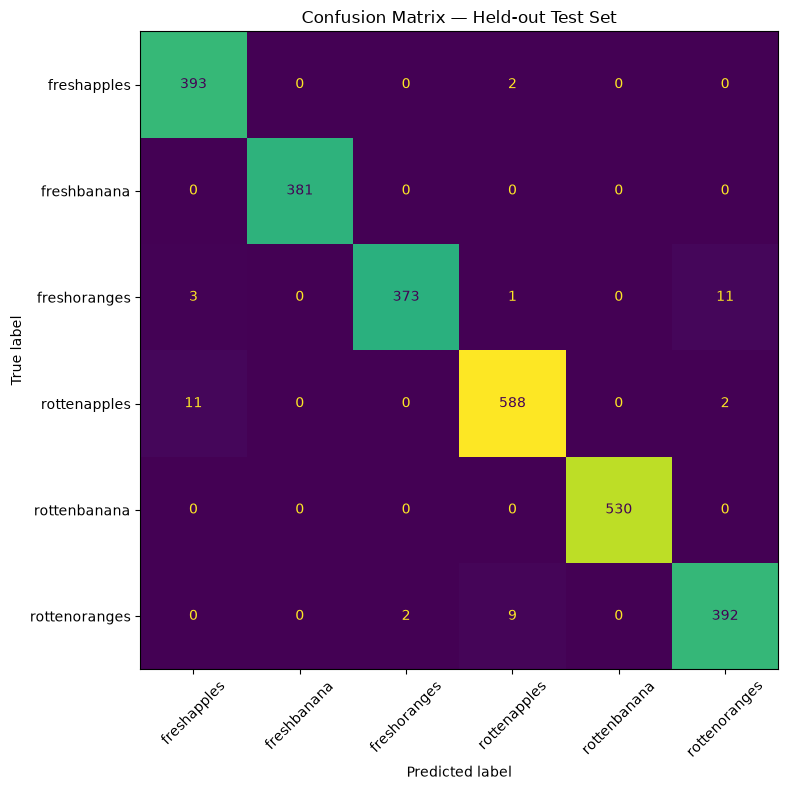

In [11]:
y_true = np.concatenate([y.numpy() for _, y in test_ds], axis=0)
probs = model.predict(test_ds, verbose=1)
y_pred = np.argmax(probs, axis=1)

print("TEST accuracy:", round(accuracy_score(y_true, y_pred), 4))
print("TEST macro F1:", round(f1_score(y_true, y_pred, average="macro", zero_division=0), 4))
print("\nPer-class metrics:")
print(classification_report(y_true, y_pred, labels=list(range(len(class_names))),
                            target_names=class_names, digits=4, zero_division=0))
cm = confusion_matrix(y_true, y_pred, labels=list(range(len(class_names))))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)
fig, ax = plt.subplots(figsize=(9, 8))
disp.plot(ax=ax, xticks_rotation=45, colorbar=False)
plt.title("Confusion Matrix — Held-out Test Set")
plt.tight_layout()
plt.show()

## 9. Display at least four misclassified test images
Use these examples in your report and explain the likely visual reason for each mistake.

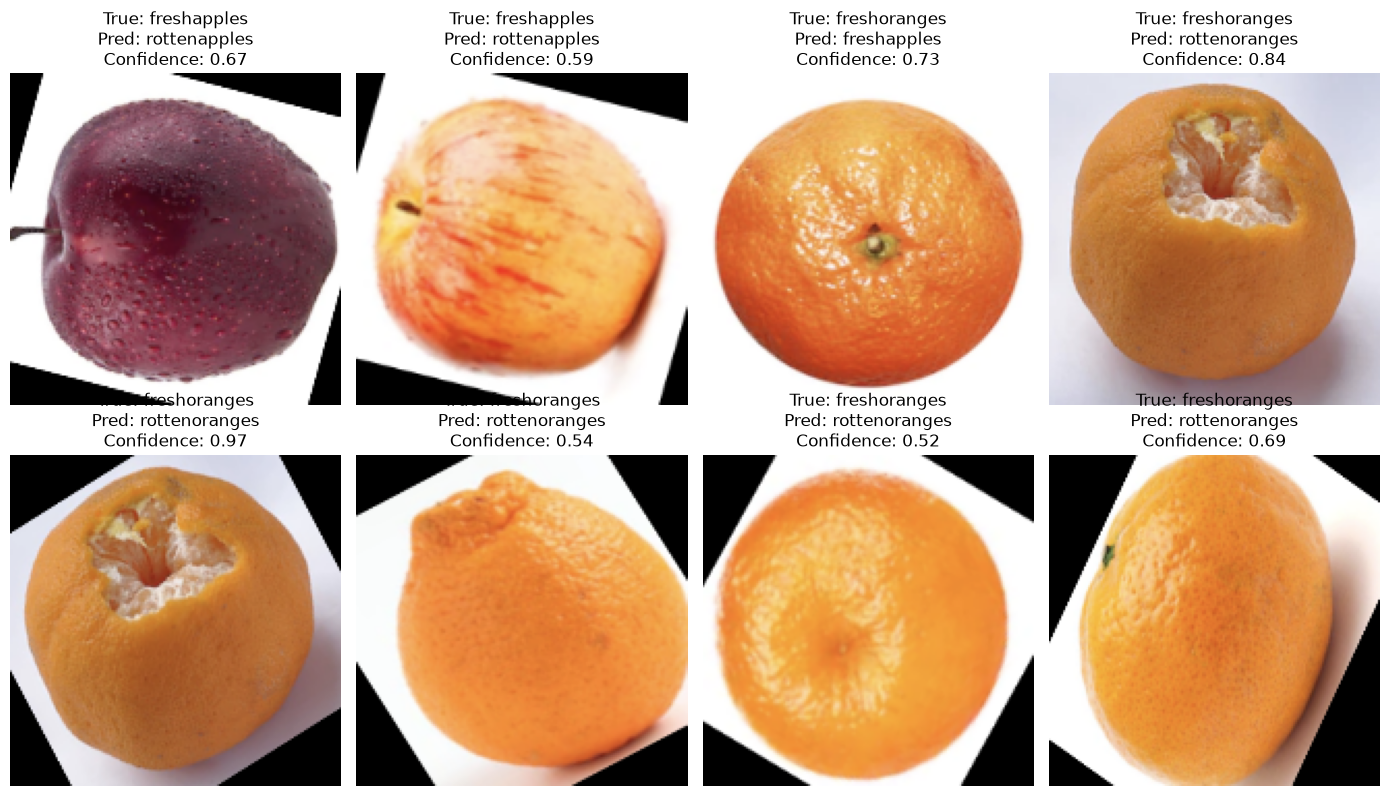

Discuss possible reasons: subtle spoilage, lighting/background, fruit angle, blur, or the model focusing on fruit type instead of freshness.


In [12]:
wrong = np.where(y_true != y_pred)[0]
if len(wrong) == 0:
    print("No misclassified test examples in this run.")
else:
    chosen = wrong[:min(8, len(wrong))]
    # Retrieve test images in the same non-shuffled order used for predictions.
    all_images = np.concatenate([x.numpy() for x, _ in test_ds], axis=0)
    n = len(chosen)
    cols = 4
    rows = int(np.ceil(n / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(14, 4 * rows))
    axes = np.array(axes).reshape(-1)
    for ax in axes:
        ax.axis("off")
    for ax, idx in zip(axes, chosen):
        ax.imshow(np.clip(all_images[idx].astype("uint8"), 0, 255))
        confidence = float(np.max(probs[idx]))
        ax.set_title(f"True: {class_names[y_true[idx]]}\nPred: {class_names[y_pred[idx]]}\nConfidence: {confidence:.2f}")
        ax.axis("off")
    plt.tight_layout()
    plt.show()
    print("Discuss possible reasons: subtle spoilage, lighting/background, fruit angle, blur, or the model focusing on fruit type instead of freshness.")

## 10. PS-12 challenge: did the model learn spoilage or fruit type?
A six-class classifier can get the fruit type right but still miss fresh/rotten condition. Use the test predictions to calculate the two aspects separately. This is a diagnostic, not a replacement for the six-class evaluation.

In [13]:
# Fruit type is apple/banana/orange; condition is fresh/rotten.
def fruit_type(label):
    s = class_names[int(label)].lower()
    if "apple" in s: return "apple"
    if "banana" in s: return "banana"
    if "orange" in s: return "orange"
    return "unknown"

def condition(label):
    return "rotten" if "rotten" in class_names[int(label)].lower() else "fresh"

true_fruit = [fruit_type(i) for i in y_true]
pred_fruit = [fruit_type(i) for i in y_pred]
true_condition = [condition(i) for i in y_true]
pred_condition = [condition(i) for i in y_pred]
print("Fruit-type accuracy:", round(accuracy_score(true_fruit, pred_fruit), 4))
print("Fresh/rotten-condition accuracy:", round(accuracy_score(true_condition, pred_condition), 4))
print("Interpretation: if fruit-type accuracy is much higher than condition accuracy, the model may be recognising fruit identity more reliably than spoilage cues.")

Fruit-type accuracy: 0.9944
Fresh/rotten-condition accuracy: 0.99
Interpretation: if fruit-type accuracy is much higher than condition accuracy, the model may be recognising fruit identity more reliably than spoilage cues.


## 11. Save the model and results
Download the notebook using **File → Download → Download .ipynb**. Save the trained model and metrics as additional project outputs.

In [14]:
model.save("PS12_fruit_freshness_model.keras")
results = {
    "test_accuracy": float(accuracy_score(y_true, y_pred)),
    "test_macro_f1": float(f1_score(y_true, y_pred, average="macro", zero_division=0)),
    "fruit_type_accuracy": float(accuracy_score(true_fruit, pred_fruit)),
    "fresh_rotten_accuracy": float(accuracy_score(true_condition, pred_condition)),
    "training_time_minutes": float(training_seconds / 60),
    "classes": class_names
}
import json
with open("PS12_results.json", "w") as f:
    json.dump(results, f, indent=2)
print(json.dumps(results, indent=2))
print("Saved model: PS12_fruit_freshness_model.keras")
print("Saved metrics: PS12_results.json")

{
  "test_accuracy": 0.9848035581912528,
  "test_macro_f1": 0.9845417410858611,
  "fruit_type_accuracy": 0.9944403261675315,
  "fresh_rotten_accuracy": 0.9899925871015567,
  "training_time_minutes": 6.432388548056284,
  "classes": [
    "freshapples",
    "freshbanana",
    "freshoranges",
    "rottenapples",
    "rottenbanana",
    "rottenoranges"
  ]
}
Saved model: PS12_fruit_freshness_model.keras
Saved metrics: PS12_results.json


## 12. Report checklist
Before submission:
- [ ] Include name, register number, section, PS-12 title, date and GitHub notebook link.
- [ ] Record dataset source, exact image counts, split sizes, input size, augmentation, model, optimizer, learning rate, batch size and epochs.
- [ ] Use actual **test** accuracy, per-class precision/recall/F1, macro F1 and confusion matrix from this notebook.
- [ ] Include training/validation curves and at least four misclassified test examples with explanations.
- [ ] Discuss whether fruit-type accuracy differs from fresh/rotten-condition accuracy.
- [ ] Mention limitations: dataset backgrounds may be easier than real sorting-line images; visible appearance does not prove food safety.
- [ ] Cite the dataset: Sriram Reddy Kalluri, *Fruits Fresh and Rotten for Classification*, Kaggle, https://www.kaggle.com/datasets/sriramr/fruits-fresh-and-rotten-for-classification
- [ ] Save the notebook as `RegisterNo_PS12.ipynb` and report as `RegisterNo_PS12_Report.pdf`.
- [ ] Declare AI assistance if required by your course instructions.